# Kalman Filter Basics

This notebook implements a minimal one-dimensional Kalman filter to demonstrate state estimation from noisy measurements.

The filter alternates between prediction and measurement-update steps.

In [2]:
# 1-11D — Environment Check

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Kalman filter environment ready.")

NumPy version: 2.4.6
Kalman filter environment ready.


## State Estimation

A state estimator combines a model of system motion with noisy measurements.

The Kalman filter uses two main stages:

1. Prediction
2. Measurement update

The prediction estimates the next state using the system model.

The measurement update corrects the prediction using a sensor measurement.

In [3]:
# 2-11D — Generate a Simple Motion Scenario

np.random.seed(42)

time_steps = np.arange(20)

true_position = 2.0 * time_steps

measurement_noise = np.random.normal(
    loc=0.0,
    scale=3.0,
    size=len(time_steps)
)

measurements = true_position + measurement_noise

print("True positions:")
print(true_position)

print("\nNoisy measurements:")
print(np.round(measurements, 2))

True positions:
[ 0.  2.  4.  6.  8. 10. 12. 14. 16. 18. 20. 22. 24. 26. 28. 30. 32. 34.
 36. 38.]

Noisy measurements:
[ 1.49  1.59  5.94 10.57  7.3   9.3  16.74 16.3  14.59 19.63 18.61 20.6
 24.73 20.26 22.83 28.31 28.96 34.94 33.28 33.76]


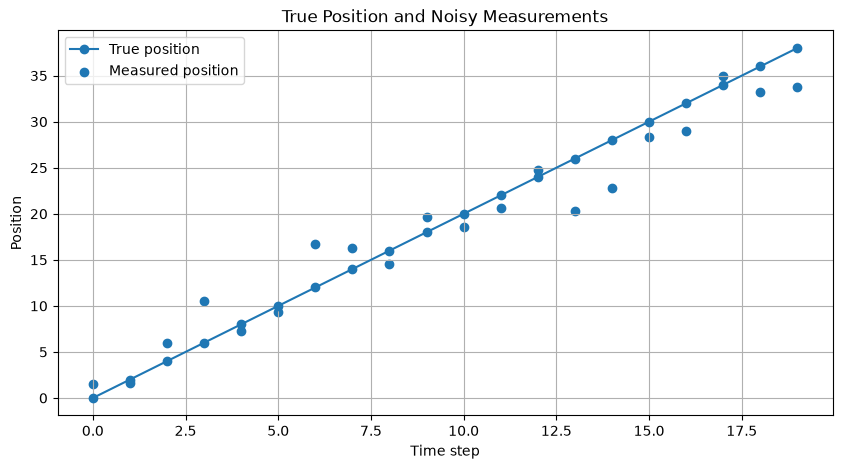

In [4]:
# 3-11D — Visualize Noisy Measurements

plt.figure(figsize=(10, 5))

plt.plot(
    time_steps,
    true_position,
    marker="o",
    label="True position"
)

plt.scatter(
    time_steps,
    measurements,
    label="Measured position"
)

plt.xlabel("Time step")
plt.ylabel("Position")
plt.title("True Position and Noisy Measurements")
plt.legend()
plt.grid()
plt.show()

## Constant-Velocity Kalman Filter

For the following experiment, the estimated state contains both position and velocity:

`x = [position, velocity]`

A constant-velocity motion model is used to predict how the state evolves between measurements.

The filter therefore uses:

- State-transition matrix `F`
- Measurement matrix `H`
- State uncertainty `P`
- Process noise covariance `Q`
- Measurement noise covariance `R`

The prediction step estimates both the future position and velocity.

The measurement update then corrects the predicted state using the measured position.

In [12]:
# 4-11D — Initialize Constant-Velocity Kalman Filter

# State: [position, velocity]
x = np.array([0.0, 0.0])

# State uncertainty
P = np.eye(2)

# State-transition matrix
F = np.array([
    [1.0, 1.0],
    [0.0, 1.0]
])

# Measurement matrix: only position is measured
H = np.array([
    [1.0, 0.0]
])

# Process noise covariance
Q = np.array([
    [0.1, 0.0],
    [0.0, 0.1]
])

# Measurement noise covariance
R = np.array([[9.0]])

estimated_positions = []

print("Initial state [position, velocity]:")
print(x)

Initial state [position, velocity]:
[0. 0.]


## Prediction Step

For the simplified constant-position model:

`x_predicted = x`

The uncertainty is increased by the process noise:

`P_predicted = P + Q`

In [13]:
# 5-11D — Prediction Step

x_prediction = F @ x
P_prediction = F @ P @ F.T + Q

print("Predicted state [position, velocity]:")
print(x_prediction)

print("\nPredicted uncertainty:")
print(P_prediction)

Predicted state [position, velocity]:
[0. 0.]

Predicted uncertainty:
[[2.1 1. ]
 [1.  1.1]]


## Measurement Update

The Kalman gain determines how strongly the new measurement influences the predicted state.

The measurement residual is the difference between the measured position and the predicted position.

The state estimate is then corrected using the Kalman gain.

This allows the filter to combine the motion model with noisy position measurements.

In [14]:
# 6-11D — Measurement Update

measurement = measurements[0]

innovation = measurement - (H @ x_prediction)[0]

S = H @ P_prediction @ H.T + R

K = P_prediction @ H.T @ np.linalg.inv(S)

x_updated = x_prediction + K.flatten() * innovation
P_updated = (np.eye(2) - K @ H) @ P_prediction

print("Measurement:", measurement)
print("Kalman gain:")
print(K.flatten())

print("\nUpdated state [position, velocity]:")
print(x_updated)

print("\nUpdated uncertainty:")
print(P_updated)

Measurement: 1.490142459033698
Kalman gain:
[0.18918919 0.09009009]

Updated state [position, velocity]:
[0.28191884 0.13424707]

Updated uncertainty:
[[1.7027027  0.81081081]
 [0.81081081 1.00990991]]


## Complete Kalman Filter

The prediction and measurement-update steps are now combined into a complete filtering loop.

The filter estimates the position at each time step from noisy measurements.

In [15]:
# 7-11D — Complete Constant-Velocity Kalman Filter

x = np.array([0.0, 0.0])
P = np.eye(2)

estimated_positions = []
estimated_velocities = []
kalman_gains = []

for measurement in measurements:

    # Prediction
    x_prediction = F @ x
    P_prediction = F @ P @ F.T + Q

    # Measurement update
    innovation = measurement - (H @ x_prediction)[0]

    S = H @ P_prediction @ H.T + R

    K = P_prediction @ H.T @ np.linalg.inv(S)

    x = x_prediction + K.flatten() * innovation
    P = (np.eye(2) - K @ H) @ P_prediction

    estimated_positions.append(x[0])
    estimated_velocities.append(x[1])
    kalman_gains.append(K[0, 0])

estimated_positions = np.array(estimated_positions)
estimated_velocities = np.array(estimated_velocities)
kalman_gains = np.array(kalman_gains)

print("Final position estimate:", estimated_positions[-1])
print("Final velocity estimate:", estimated_velocities[-1])
print("Final position uncertainty:", P[0, 0])

Final position estimate: 34.84238814903659
Final velocity estimate: 1.7869413240135912
Final position uncertainty: 3.391753642645268


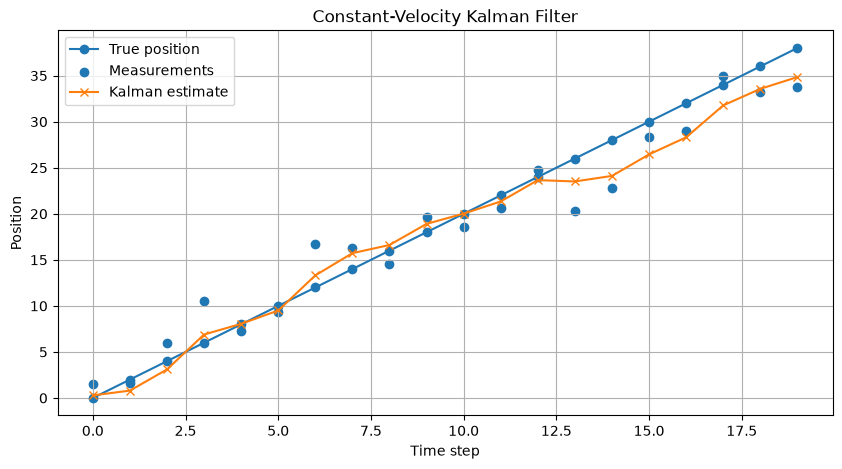

In [16]:
# 8-11D — Compare True, Measured, and Estimated Position

plt.figure(figsize=(10, 5))

plt.plot(
    time_steps,
    true_position,
    marker="o",
    label="True position"
)

plt.scatter(
    time_steps,
    measurements,
    label="Measurements"
)

plt.plot(
    time_steps,
    estimated_positions,
    marker="x",
    label="Kalman estimate"
)

plt.xlabel("Time step")
plt.ylabel("Position")
plt.title("Constant-Velocity Kalman Filter")
plt.legend()
plt.grid()
plt.show()

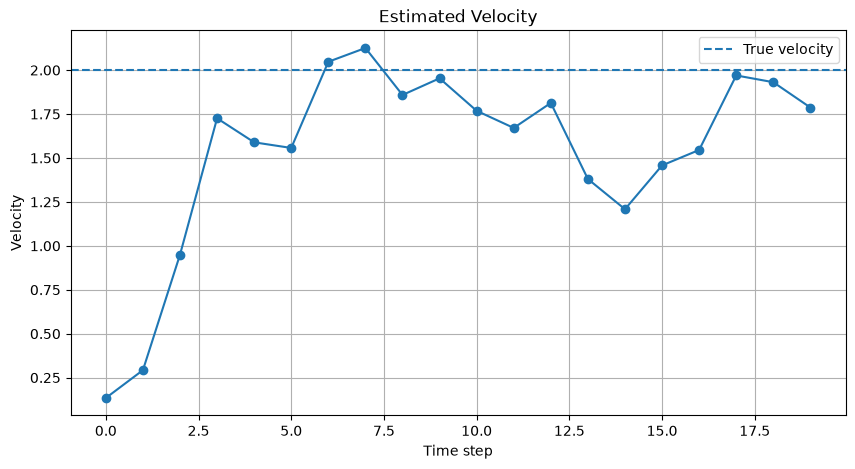

In [17]:
# 9-11D — Estimated Velocity and Kalman Gain

plt.figure(figsize=(10, 5))

plt.plot(
    time_steps,
    estimated_velocities,
    marker="o"
)

plt.axhline(
    2.0,
    linestyle="--",
    label="True velocity"
)

plt.xlabel("Time step")
plt.ylabel("Velocity")
plt.title("Estimated Velocity")
plt.legend()
plt.grid()
plt.show()

## State Estimation — Observation

The Kalman filter produces a smoothed state estimate from noisy measurements.

The Kalman gain controls the balance between the predicted state and the new measurement. As the filter processes additional measurements, the uncertainty converges toward a stable value for the selected process and measurement-noise assumptions.

In [18]:
# 10-11D — Quantitative Comparison

measurement_mae = np.mean(
    np.abs(measurements - true_position)
)

estimate_mae = np.mean(
    np.abs(estimated_positions - true_position)
)

print("Mean absolute error:")
print(f"Raw measurements: {measurement_mae:.3f}")
print(f"Kalman estimate:  {estimate_mae:.3f}")

print("\nFinal estimated velocity:")
print(f"{estimated_velocities[-1]:.3f} pixels/time step")

Mean absolute error:
Raw measurements: 2.348
Kalman estimate:  1.542

Final estimated velocity:
1.787 pixels/time step


## Kalman Filter — Conclusion

The experiment demonstrated the basic prediction and measurement-update cycle of a Kalman filter using a constant-velocity motion model.

For the simulated noisy measurements, the mean absolute error decreased from 2.348 for the raw measurements to 1.542 for the Kalman-filter estimate. The final estimated velocity was 1.787 pixels/time step, approaching the simulated constant velocity of 2 pixels/time step.

The experiment demonstrates how a motion model and noisy measurements can be combined to obtain a more stable state estimate.

This one-dimensional example is intentionally simplified. A vehicle state estimator would normally use a multi-dimensional state, a motion model, and measurements from sensors such as wheel odometry, IMU, GNSS, camera, or lidar.

The experiment provides the foundation for later tracking and localization work.